# 1. Setup & Environment Initialisation

## Overview
This notebook trains a single **LightGBM** model: the **Escalation Risk Predictor**. It predicts whether an incoming support ticket will breach its SLA before resolution (`0 = No Risk`, `1 = At Risk`).

## Key Design Decisions

### 1. Why Only One Model (and Why Urgency Was Removed)
Urgency has no real ground truth in our dataset. Any urgency labels we could generate would be synthetic probability distributions where identical features could receive different labels purely by random chance, creating noisy, unlearnable signals.
In contrast, `escalation_label` is derived from the `escalated` column in `resolved_tickets_clean.csv`. That column was generated by our synthetic data generator (escalated = resolution time > 120 minutes, where resolution time is a template base time with +/-30% random variation). It is synthetic. On real data this model must be retrained on actual SLA outcomes.

### 2. Complexity Is an Input Feature, Not a Prediction Target
Technical complexity is already predicted directly from ticket text by our fine-tuned **BERT** classifier. In LightGBM, `complexity` is used strictly as an **input feature**. During training, it is derived via `COMPLEXITY_MAP` as a direct proxy for BERT's output.

### 3. Candidate Calendar & Historical Features
Calendar features (`is_month_end`, `is_quarter_end`, `day_of_week`) are candidate features. In our synthetic data `created_date` is random, so they are not expected to carry signal. The signal check cell tests this. In production, real timestamps from Nexus HRMS would be used.
For `client_escalation_history`: in this dataset it is a chronological per-module running count of past escalations, because we have no client IDs. In production it should be a per-client rolling count.

## Inference Pipeline Flow
```
Ticket arrives
  │
  ▼
Stage 0 (Intake Routing - DistilBERT):
  DistilBERT runs on raw ticket text to classify ticket_type (incident vs development)
  - Development tickets are routed out immediately (not processed by LightGBM/RAG)
  - Incident tickets proceed to Stage 1
  │
  ▼
Stage 1: BERT runs on ticket text
  └── Outputs: module, issue_type, complexity
  │
  ▼
Stage 2: LightGBM runs on BERT outputs + ticket metadata
  └── Inputs:  module, issue_type, complexity, text_length_words,
               has_error_code, day_of_week, is_month_end, is_quarter_end,
               client_escalation_history
  └── Outputs: escalation risk probability (0.0 to 1.0)
  │
  ▼
Stage 3: Dashboard displays all predictions to support consultant
```

In [1]:
# Install required dependencies for LightGBM training, data manipulation, and visualization
# lightgbm: Fast gradient boosted decision tree framework
# scikit-learn: Dataset splitting, performance metrics, and evaluation tools
# pandas: Tabular dataframe operations and CSV manipulation
# numpy: Array computations and numerical operations
# matplotlib & seaborn: Statistical data visualization and diagnostic charts
# joblib: Efficient model serialization and disk persistence
!pip install lightgbm scikit-learn pandas numpy matplotlib seaborn joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Standard library imports
import json
import os
import random
import shutil
from datetime import datetime

# Numerical and tabular processing
import numpy as np
import pandas as pd

# Gradient boosting and model persistence
import joblib
import lightgbm as lgb

# Dataset splitting and performance evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set deterministic random seeds for full reproducibility across all libraries
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Global visualization styling
sns.set_theme(style="darkgrid")

print("Environment configured successfully. Random seeds fixed to 42.")

Environment configured successfully. Random seeds fixed to 42.


# 2. Data Loading & Feature Engineering

## Overview
In this section we load the cleaned ticket CSVs (`incoming_tickets_clean.csv` and `resolved_tickets_clean.csv`), perform an inner join on `ticket_id`, filter out development tickets (which are routed out at Stage 0 by DistilBERT), and engineer feature variables for LightGBM training.

In [3]:
# ── FILE PATH DEFINITIONS ──────────────────────────────────────────────────────
# Input clean datasets produced by data inspection
INCOMING_CSV     = "../data/synthetic/incoming_tickets_clean.csv"
RESOLVED_CSV     = "../data/synthetic/resolved_tickets_clean.csv"
BACKEND_LGBM_DIR = "../backend/models/lightgbm"

# LightGBM output artifact paths (flat filenames)
ESCALATION_MODEL_PATH = "lightgbm_escalation_model.pkl"
FEATURE_NAMES_PATH    = "lightgbm_feature_names.json"
MODELS_META_PATH      = "lightgbm_models_meta.json"

# Complexity mapping — identical mapping used during BERT classifier training
# At inference time, BERT predicts complexity directly from raw text.
# At LightGBM training time, we derive it from issue_type as a close proxy
# because BERT learned from this exact mapping.
COMPLEXITY_MAP = {
    "Authorization":      "Simple",
    "User Error":         "Simple",
    "Master Data":        "Simple",
    "Configuration":      "Medium",
    "Data Inconsistency": "Medium",
    "Performance":        "Medium",
    "System Error":       "Complex",
    "Integration":        "Complex",
}
COMPLEXITY_LABELS = {"Simple": 0, "Medium": 1, "Complex": 2}

print("File paths and complexity mappings configured successfully.")

File paths and complexity mappings configured successfully.


In [4]:
# Load clean incoming and resolved datasets
df_in  = pd.read_csv(INCOMING_CSV)
df_res = pd.read_csv(RESOLVED_CSV)

print(f"Incoming clean CSV: {len(df_in):,} rows")
print(f"Resolved clean CSV: {len(df_res):,} rows")

# Filter to incident and edge_case only
# Development tickets are routed out by DistilBERT at Stage 0
# LightGBM never sees development tickets at inference time
df_in = df_in[
    df_in["ticket_type"].isin(["incident", "edge_case"])
].copy()
print(f"After filtering development tickets: {len(df_in):,} rows")

# Join on ticket_id to retrieve escalation outcomes and dates
# Inner join ensures only tickets with full resolution data are used
df = df_in.merge(
    df_res[[
        "ticket_id", "escalated",
        "created_date", "resolved_date",
        "resolution_time_minutes"
    ]],
    on="ticket_id", how="inner"
)
df = df.reset_index(drop=True)

print(f"After join: {len(df):,} rows")
print(f"Columns: {list(df.columns)}")
df.head(3)

Incoming clean CSV: 24,252 rows
Resolved clean CSV: 18,102 rows
After filtering development tickets: 18,102 rows
After join: 18,102 rows
Columns: ['ticket_id', 'text', 'ticket_type', 'module', 'issue_type', 'has_error_code', 'error_code', 'escalated', 'created_date', 'resolved_date', 'resolution_time_minutes']


,ticket_id,text,ticket_type,module,issue_type,has_error_code,error_code,escalated,created_date,resolved_date,resolution_time_minutes
0,INC-010691,Im trying to get this PO to release but it won...,incident,MM,Configuration,False,NaN,No,2025-08-24,2025-08-28,62
1,INC-011536,"Need help ASAP with leave quotas, they are not...",incident,HR,Configuration,False,NaN,No,2026-04-07,2026-04-07,81
2,INC-012122,HELP URGENT!! Sales order wont save and keeps ...,incident,SD,System Error,True,V1 032,No,2025-12-07,2025-12-07,59


In [5]:
# Sort chronologically — required for client_escalation_history
# which calculates a cumulative count of past module escalations
df["created_date"]  = pd.to_datetime(df["created_date"])
df["resolved_date"] = pd.to_datetime(df["resolved_date"])
df = df.sort_values("created_date").reset_index(drop=True)

# ── ESCALATION LABEL ──────────────────────────────────────────────────────────
# Derived from the synthetic escalated column: Yes -> 1 (breached SLA), No -> 0 (within SLA)
df["escalation_label"] = (
    df["escalated"].str.strip().str.upper() == "YES"
).astype(int)

print("Escalation label distribution (from synthetic data):")
print(df["escalation_label"].value_counts())
print(f"Overall escalation rate: {df['escalation_label'].mean()*100:.1f}%\n")
print("Escalation rate by module:")
print(df.groupby("module")["escalation_label"].mean().sort_values(ascending=False))

# ── TEXT FEATURE ──────────────────────────────────────────────────────────────
# Word count of ticket description — longer tickets correlate with more complex issues
df["text_length_words"] = df["text"].apply(lambda x: len(str(x).split()))

# ── ERROR CODE FEATURE ────────────────────────────────────────────────────────
# Binary indicator for SAP error codes in ticket text
df["has_error_code"] = df["has_error_code"].astype(int)

# ── COMPLEXITY FEATURE (PROXY FOR BERT INFERENCE) ─────────────────────────────
# Mapped to integer: Simple=0, Medium=1, Complex=2
df["complexity"] = (
    df["issue_type"]
    .map(COMPLEXITY_MAP)
    .map(COMPLEXITY_LABELS)
    .fillna(1)
    .astype(int)
)

# ── DATE-DERIVED CALENDAR FEATURES ────────────────────────────────────────────
# Extracted from created_date. Candidate features; random in synthetic data.
df["day_of_week"]  = df["created_date"].dt.dayofweek  # 0=Monday, 4=Friday, 6=Sunday
df["day_of_month"] = df["created_date"].dt.day
df["month"]        = df["created_date"].dt.month

# is_month_end: ticket arrived during month-end close (day 28-31)
df["is_month_end"] = (df["day_of_month"] >= 28).astype(int)

# is_quarter_end: month-end in a quarter-closing month (March, June, September, December)
df["is_quarter_end"] = (
    (df["is_month_end"] == 1) &
    (df["month"].isin([3, 6, 9, 12]))
).astype(int)

# ── CLIENT ESCALATION HISTORY ─────────────────────────────────────────────────
# In this dataset it is a chronological per-module running count of past escalations,
# because we have no client IDs. In production it should be a per-client rolling count.
# shift(1) strictly excludes the current ticket to prevent target leakage.
df["client_escalation_history"] = (
    df.groupby("module")["escalation_label"]
    .transform(lambda x: x.shift(1).cumsum().fillna(0))
    .astype(int)
)

# ── RESOLUTION TIME (DATA QUALITY SANITY CHECK ONLY) ──────────────────────────
# resolution_time_minutes is NOT an inference feature because it is unknown
# when a new ticket arrives. Used here only to verify synthetic label construction.
df["resolution_time_minutes"] = pd.to_numeric(
    df["resolution_time_minutes"], errors="coerce"
).fillna(df["resolution_time_minutes"].median())

print("\nResolution time by escalation label (sanity check):")
print(df.groupby("escalation_label")["resolution_time_minutes"].describe())
print("Escalated tickets (1) should show higher resolution times than non-escalated (0).")

# Derived feature distribution summary
print(f"\nis_month_end=1: {df['is_month_end'].sum():,} tickets ({df['is_month_end'].mean()*100:.1f}%)")
print(f"is_quarter_end=1: {df['is_quarter_end'].sum():,} tickets ({df['is_quarter_end'].mean()*100:.1f}%)")
print(f"day_of_week distribution:\n{df['day_of_week'].value_counts().sort_index()}")
print(f"\ncomplexity distribution:\n{df['complexity'].value_counts().sort_index()}")

Escalation label distribution (from synthetic data):
escalation_label
0    16887
1     1215
Name: count, dtype: int64
Overall escalation rate: 6.7%

Escalation rate by module:
module
ABAP     0.360319
HR       0.074405
SD       0.046729
FI       0.046229
PP       0.030864
MM       0.022609
BASIS    0.000000
Name: escalation_label, dtype: float64

Resolution time by escalation label (sanity check):
                    count        mean        std    min    25%    50%    75%  \
escalation_label                                                               
0                 16887.0   66.710606  27.661137   14.0   42.0   67.0   90.0   
1                  1215.0  137.912757  16.176150  121.0  126.0  134.0  145.0   

                    max  
escalation_label         
0                 120.0  
1                 194.0  
Escalated tickets (1) should show higher resolution times than non-escalated (0).

is_month_end=1: 2,037 tickets (11.3%)
is_quarter_end=1: 802 tickets (4.4%)
day_of_week dist

In [6]:
# Features available at INFERENCE TIME when a new ticket arrives
# Note: resolution_time_minutes is deliberately excluded
INFERENCE_FEATURES = [
    "complexity",                  # predicted by BERT from ticket text
    "has_error_code",              # extracted from ticket preprocessing
    "text_length_words",           # calculated from ticket text
    "day_of_week",                 # timestamp context on arrival
    "is_month_end",                # calendar flag on arrival
    "is_quarter_end",              # calendar flag on arrival
    "client_escalation_history",   # historical rolling module escalation count
]

# Categorical features to one-hot encode (predicted by BERT at inference time)
CATEGORICAL_FEATURES = ["module", "issue_type"]

# One-hot encode module and issue_type
# drop_first=False keeps all dummy columns so no feature column is absent at inference
df_encoded = pd.get_dummies(
    df[INFERENCE_FEATURES + CATEGORICAL_FEATURES],
    columns    = CATEGORICAL_FEATURES,
    drop_first = False,
    dtype      = int,
)

X = df_encoded.copy()
y = df["escalation_label"].copy()

# Save exact feature names — backend will construct feature vector in this exact order
feature_names = list(X.columns)
with open(FEATURE_NAMES_PATH, "w") as f:
    json.dump({"feature_names": feature_names}, f, indent=2)

print(f"Feature matrix shape: {X.shape}")
print(f"Total features: {len(feature_names)}")
print(f"\nFeature names ({len(feature_names)}):\n")
for name in feature_names:
    print(f"  {name}")

Feature matrix shape: (18102, 22)
Total features: 22

Feature names (22):

  complexity
  has_error_code
  text_length_words
  day_of_week
  is_month_end
  is_quarter_end
  client_escalation_history
  module_ABAP
  module_BASIS
  module_FI
  module_HR
  module_MM
  module_PP
  module_SD
  issue_type_Authorization
  issue_type_Configuration
  issue_type_Data Inconsistency
  issue_type_Integration
  issue_type_Master Data
  issue_type_Performance
  issue_type_System Error
  issue_type_User Error


## Leakage Guard & Empirical Signal Check
These checks guard against target leakage (ensuring post-resolution features are never passed into the feature matrix `X`) and test which candidate features carry empirical signal in the dataset.

In [7]:
# ── DATA LEAKAGE GUARD ─────────────────────────────────────────────────────────
# Guard against leakage: ensure no post-resolution fields are passed in feature matrix X
FORBIDDEN_FEATURES = {
    "resolution_time_minutes",
    "escalated",
    "escalation_label",
    "resolved_date",
    "created_date",
}
assert FORBIDDEN_FEATURES.isdisjoint(X.columns), (
    f"Leakage: {FORBIDDEN_FEATURES & set(X.columns)}"
)
print("Leakage guard passed: no post-resolution columns in X")

# ── SIGNAL CHECK ──────────────────────────────────────────────────────────────
# Check empirical escalation rates across categories vs candidate calendar features.
# If module+issue_type rates vary widely while calendar features are flat,
# the signal comes from module and issue type only (synthetic created_date is random).
print("\nEscalation rate by module + issue_type (top 15):")
print(
    df.groupby(["module", "issue_type"])["escalation_label"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
    .head(15)
)

for col in ["is_month_end", "is_quarter_end", "day_of_week"]:
    print(f"\nEscalation rate by {col}:")
    print(df.groupby(col)["escalation_label"].agg(["mean", "count"]))

Leakage guard passed: no post-resolution columns in X

Escalation rate by module + issue_type (top 15):
                               mean  count
module issue_type                         
ABAP   Performance         0.825581    258
       System Error        0.531207    721
HR     System Error        0.523013    239
FI     Data Inconsistency  0.469231    260
MM     Data Inconsistency  0.301158    259
SD     Integration         0.169275    703
FI     Integration         0.158996    239
PP     Configuration       0.154440    259
ABAP   Data Inconsistency  0.140625    256
PP     Data Inconsistency  0.062893    477
SD     Configuration       0.042292    733
ABAP   Integration         0.000000    260
BASIS  Authorization       0.000000    519
ABAP   Configuration       0.000000    259
FI     Authorization       0.000000    968

Escalation rate by is_month_end:
                  mean  count
is_month_end                 
0             0.067102  16065
1             0.067256   2037

Escalation

In [8]:
# ── DATASET SUMMARY & CLASS DISTRIBUTION ──────────────────────────────────────
# Check class distribution and compute random baseline for Precision-Recall AUC
neg_count = (y == 0).sum()
pos_count = (y == 1).sum()
pos_rate  = pos_count / len(y)

print("═" * 55)
print("DATASET SUMMARY")
print("═" * 55)
print(f"Total tickets:        {len(df):,}")
print(f"Incident tickets:     {(df['ticket_type']=='incident').sum():,}")
print(f"Edge case tickets:    {(df['ticket_type']=='edge_case').sum():,}")
print()
print("Escalation label (derived from synthetic escalated column):")
print(f"  No Risk (0): {neg_count:,} ({neg_count/len(y)*100:.1f}%)")
print(f"  At Risk (1): {pos_count:,} ({pos_count/len(y)*100:.1f}%)")
print(f"PR-AUC baseline (random classifier) = positive rate = {pos_rate:.4f}")
print()
print("NOTE: escalation_label is derived from the synthetic escalated column.")
print("═" * 55)

═══════════════════════════════════════════════════════
DATASET SUMMARY
═══════════════════════════════════════════════════════
Total tickets:        18,102
Incident tickets:     14,702
Edge case tickets:    3,400

Escalation label (derived from synthetic escalated column):
  No Risk (0): 16,887 (93.3%)
  At Risk (1): 1,215 (6.7%)
PR-AUC baseline (random classifier) = positive rate = 0.0671

NOTE: escalation_label is derived from the synthetic escalated column.
═══════════════════════════════════════════════════════


# 3. Escalation Risk Model Training

## Model Architecture & Loss Objective
- **Objective**: Binary classification (`0 = No Risk`, `1 = At Risk`) using `binary_logloss`.
- **Target Source**: `escalation_label` is derived from the `escalated` column in `resolved_tickets_clean.csv`. That column was generated by our synthetic data generator (escalated = resolution time > 120 minutes, where resolution time is a template base time with +/-30% random variation). It is synthetic. On real data this model must be retrained on actual SLA outcomes.
- **Candidate Features**: Calendar features are candidate features. In our synthetic data `created_date` is random, so they are not expected to carry signal. The signal check cell tests this. In production, real timestamps from Nexus HRMS would be used.
- **Calibration & Imbalance Handling**: Rather than using `scale_pos_weight` (which distorts predicted probabilities and clashes with unweighted early stopping), the model trains with unweighted logloss to produce calibrated risk scores. Class imbalance is handled by tuning the decision threshold on validation data.
- **Key Metric (Recall)**: For escalation risk, **Recall (At Risk)** is the critical metric — missing an at-risk ticket (false negative) causes an SLA breach, which is far more costly than an operational false alarm.

In [9]:
# Stratified train/validation/test split (80% train, 10% validation, 10% test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train split: {len(X_train):,} | Validation split: {len(X_val):,} | Test split: {len(X_test):,}")
print("\nClass distribution in test set:")
print(f"  No Risk (0): {(y_test == 0).sum():,} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  At Risk (1): {(y_test == 1).sum():,} ({(y_test == 1).mean()*100:.1f}%)")

Train split: 14,481 | Validation split: 1,810 | Test split: 1,811

Class distribution in test set:
  No Risk (0): 1,689 (93.3%)
  At Risk (1): 122 (6.7%)


In [10]:
# Hyperparameters for Escalation Risk Model
# scale_pos_weight removed. It inflates predicted probabilities, and early stopping on unweighted validation
# loss pulled them back down so the model never predicted At Risk at 0.5. Without it, probabilities stay
# calibrated (0.25 means about 25% risk), which suits a dashboard risk score. Class imbalance is handled
# by tuning the decision threshold instead.
ESCALATION_PARAMS = {
    "objective":         "binary",          # Binary classification task
    "metric":            "binary_logloss",  # Log loss metric used for early stopping
    "n_estimators":      500,               # Maximum number of boosting iterations
    "learning_rate":     0.05,              # Shrinkage step size to avoid overfitting
    "max_depth":         6,                 # Maximum tree depth limit
    "num_leaves":        31,                # Maximum leaf nodes per tree (leaf-wise growth)
    "min_child_samples": 20,                # Minimum samples per leaf node
    "feature_fraction":  0.8,               # Randomly sample 80% features per tree
    "bagging_fraction":  0.8,               # Randomly sample 80% of data rows
    "bagging_freq":      5,                 # Perform bagging every 5 iterations
    "lambda_l1":         0.1,               # L1 regularization parameter
    "lambda_l2":         0.1,               # L2 regularization parameter
    "random_state":      SEED,              # Fixed seed
    "verbose":           -1,                # Suppress internal library logging
    "n_jobs":            -1,                # Utilize all available CPU cores
}

escalation_model = lgb.LGBMClassifier(**ESCALATION_PARAMS)

# Train model with early stopping if validation loss does not improve for 50 rounds
escalation_model.fit(
    X_train, y_train,
    eval_set  = [(X_val, y_val)],
    callbacks = [lgb.early_stopping(50), lgb.log_evaluation(100)],
)

print(f"Best iteration: {escalation_model.best_iteration_}")
print(f"Trees built: {escalation_model.best_iteration_}")

# Save best model checkpoint immediately
joblib.dump(escalation_model, ESCALATION_MODEL_PATH)
print(f"Model saved: {ESCALATION_MODEL_PATH}")

C:\ARIA\ARIA\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.109844
Early stopping, best iteration is:
[149]	valid_0's binary_logloss: 0.108922
Best iteration: 149
Trees built: 149
Model saved: lightgbm_escalation_model.pkl


## Predicted Probability Diagnostic
Inspect the distribution of predicted probabilities across true classes for both validation and test sets. This reveals whether scores for At Risk tickets sit above No Risk tickets even when below the default 0.5 threshold.

In [11]:
# ── PROBABILITY DIAGNOSTIC ────────────────────────────────────────────────────
# Check whether predicted probability distributions separate the two classes
val_proba  = escalation_model.predict_proba(X_val)[:, 1]
test_proba = escalation_model.predict_proba(X_test)[:, 1]

print(f"Best iteration: {escalation_model.best_iteration_}")
for label, name in [(0, "No Risk"), (1, "At Risk")]:
    p = test_proba[y_test.values == label]
    print(f"{name}: min={p.min():.3f} mean={p.mean():.3f} max={p.max():.3f}")

print(f"Test tickets with probability >= 0.5: {(test_proba >= 0.5).sum()}")

Best iteration: 149
No Risk: min=0.000 mean=0.041 max=0.838
At Risk: min=0.033 mean=0.445 max=0.882
Test tickets with probability >= 0.5: 84


## Decision Threshold Selection (Validation Set Only)
The default 0.5 cutoff assumes balanced classes and calibrated scores; neither holds under class imbalance. We tune the threshold on the validation set to meet our minimum recall target. The test set must never be used to choose the threshold, otherwise test metrics would be biased.

In [12]:
# ── DECISION THRESHOLD SELECTION (VALIDATION SET ONLY) ─────────────────────────
# Find the highest threshold meeting the recall target on validation data,
# maximizing precision while catching at-risk tickets.
MIN_RECALL_TARGET = 0.70

def select_threshold(y_true, proba, min_recall=MIN_RECALL_TARGET):
    """Highest threshold with recall >= min_recall (max precision 
    among those). Falls back to max F2 if none qualifies."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    precision, recall = precision[:-1], recall[:-1]  # align with thresholds
    meets = recall >= min_recall
    if meets.any():
        idx = int(np.argmax(np.where(meets, precision, -1)))
        return float(thresholds[idx]), "recall_target"
    f2 = 5 * precision * recall / np.maximum(4 * precision + recall, 1e-12)
    return float(thresholds[int(np.argmax(f2))]), "max_f2"

decision_threshold, threshold_method = select_threshold(y_val, val_proba)
print(f"Selected threshold: {decision_threshold:.4f} ({threshold_method})")

print("\nValidation trade-off table:")
for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (val_proba >= t).astype(int)
    print(
        f"t={t:.2f} flagged={pred.sum():4d} "
        f"precision={precision_score(y_val, pred, zero_division=0):.3f} "
        f"recall={recall_score(y_val, pred, zero_division=0):.3f}"
    )

Selected threshold: 0.3769 (recall_target)

Validation trade-off table:
t=0.05 flagged= 377 precision=0.318 recall=0.992
t=0.10 flagged= 296 precision=0.392 recall=0.959
t=0.15 flagged= 223 precision=0.466 recall=0.860
t=0.20 flagged= 183 precision=0.541 recall=0.818
t=0.25 flagged= 168 precision=0.571 recall=0.793
t=0.30 flagged= 156 precision=0.609 recall=0.785
t=0.40 flagged= 132 precision=0.598 recall=0.653
t=0.50 flagged=  87 precision=0.632 recall=0.455


In [13]:
# ── TEST SET EVALUATION AT SELECTED THRESHOLD ──────────────────────────────────
# Apply tuned decision_threshold from validation set to evaluate generalisation
test_preds = (test_proba >= decision_threshold).astype(int)

# Accuracy is shown for completeness only: the always-No-Risk baseline already scores ~0.93
esc_accuracy    = accuracy_score(y_test, test_preds)
esc_f1_weighted = f1_score(y_test, test_preds, average="weighted")
esc_f1_macro    = f1_score(y_test, test_preds, average="macro")
esc_precision   = precision_score(y_test, test_preds, zero_division=0)
esc_recall      = recall_score(y_test, test_preds, zero_division=0)
esc_f1_at_risk  = f1_score(y_test, test_preds, pos_label=1, zero_division=0)
auc_score       = roc_auc_score(y_test, test_proba)
pr_auc          = average_precision_score(y_test, test_proba)
pr_baseline     = (y_test == 1).mean()

print("ESCALATION MODEL — TEST SET RESULTS")
print("═" * 55)
print(f"Decision Threshold:    {decision_threshold:.4f} ({threshold_method})")
print(f"Accuracy (Baseline ~0.93): {esc_accuracy:.4f}")
print(f"F1 Weighted:           {esc_f1_weighted:.4f}")
print(f"F1 Macro:              {esc_f1_macro:.4f}")
print(f"Precision (At Risk):   {esc_precision:.4f}")
print(f"Recall (At Risk):      {esc_recall:.4f}")
print(f"F1 (At Risk):          {esc_f1_at_risk:.4f}")
print(f"ROC-AUC Score:         {auc_score:.4f}")
print(f"PR-AUC Score:          {pr_auc:.4f} (Baseline = {pr_baseline:.4f})")
print()
print("Classification Report (Threshold = {:.4f}):".format(decision_threshold))
print(classification_report(
    y_test, test_preds,
    target_names=["No Risk", "At Risk"],
    zero_division=0
))

# Target performance checks
print("Target Assessments:")
if auc_score >= 0.80:
    print(f"  TARGET MET: ROC-AUC {auc_score:.4f} >= 0.80")
else:
    print(f"  WARNING: ROC-AUC {auc_score:.4f} below target 0.80")

if esc_recall >= 0.70:
    print(f"  TARGET MET: At Risk Recall {esc_recall:.4f} >= 0.70 (Generalised from Validation)")
else:
    print(f"  WARNING: At Risk Recall {esc_recall:.4f} below target 0.70")

if pr_auc > pr_baseline:
    print(f"  TARGET MET: PR-AUC {pr_auc:.4f} > baseline {pr_baseline:.4f}")
else:
    print(f"  WARNING: PR-AUC {pr_auc:.4f} <= baseline {pr_baseline:.4f}")

ESCALATION MODEL — TEST SET RESULTS
═══════════════════════════════════════════════════════
Decision Threshold:    0.3769 (recall_target)
Accuracy (Baseline ~0.93): 0.9409
F1 Weighted:           0.9423
F1 Macro:              0.7759
Precision (At Risk):   0.5556
Recall (At Risk):      0.6148
F1 (At Risk):          0.5837
ROC-AUC Score:         0.9620
PR-AUC Score:          0.6216 (Baseline = 0.0674)

Classification Report (Threshold = 0.3769):
              precision    recall  f1-score   support

     No Risk       0.97      0.96      0.97      1689
     At Risk       0.56      0.61      0.58       122

    accuracy                           0.94      1811
   macro avg       0.76      0.79      0.78      1811
weighted avg       0.94      0.94      0.94      1811

Target Assessments:
  TARGET MET: ROC-AUC 0.9620 >= 0.80
  TARGET MET: PR-AUC 0.6216 > baseline 0.0674


## 5-Fold Cross-Validation (Stability Estimate)
The held-out test set contains approximately 120 positive cases, making a single split prone to sampling variance. Stratified 5-fold cross-validation on train + validation data (leaving the test set completely untouched) provides a robust stability estimate for PR-AUC and ROC-AUC.

In [14]:
# ── 5-FOLD STRATIFIED CROSS-VALIDATION ─────────────────────────────────────────
# Train + validation set combined for CV stability estimation (test set untouched)
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

cv_params = {
    **ESCALATION_PARAMS,
    "n_estimators": max(escalation_model.best_iteration_, 50),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ap_scores, auc_scores = [], []
for tr_idx, te_idx in skf.split(X_trval, y_trval):
    m = lgb.LGBMClassifier(**cv_params)
    m.fit(X_trval.iloc[tr_idx], y_trval.iloc[tr_idx])
    p = m.predict_proba(X_trval.iloc[te_idx])[:, 1]
    ap_scores.append(average_precision_score(y_trval.iloc[te_idx], p))
    auc_scores.append(roc_auc_score(y_trval.iloc[te_idx], p))

cv_pr_auc_mean, cv_pr_auc_std = float(np.mean(ap_scores)), float(np.std(ap_scores))
cv_auc_mean, cv_auc_std       = float(np.mean(auc_scores)), float(np.std(auc_scores))

print(f"5-Fold CV PR-AUC:  {cv_pr_auc_mean:.4f} +/- {cv_pr_auc_std:.4f}")
print(f"5-Fold CV ROC-AUC: {cv_auc_mean:.4f} +/- {cv_auc_std:.4f}")

5-Fold CV PR-AUC:  0.6023 +/- 0.0346
5-Fold CV ROC-AUC: 0.9605 +/- 0.0023


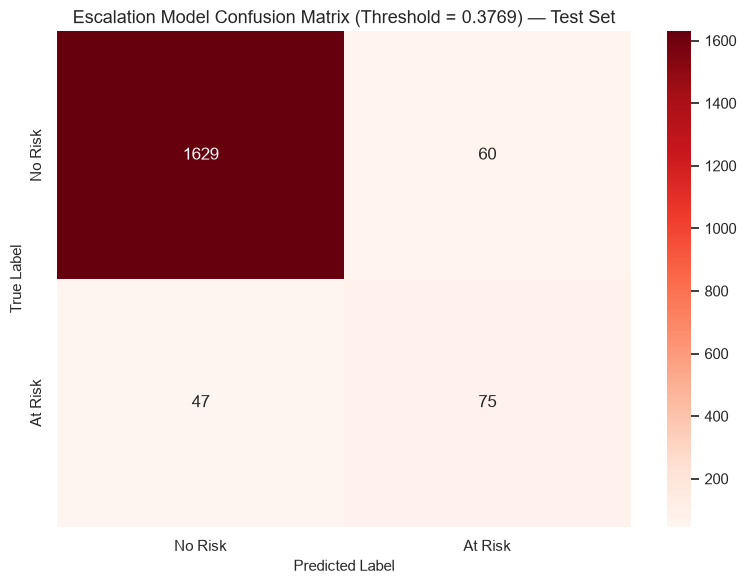

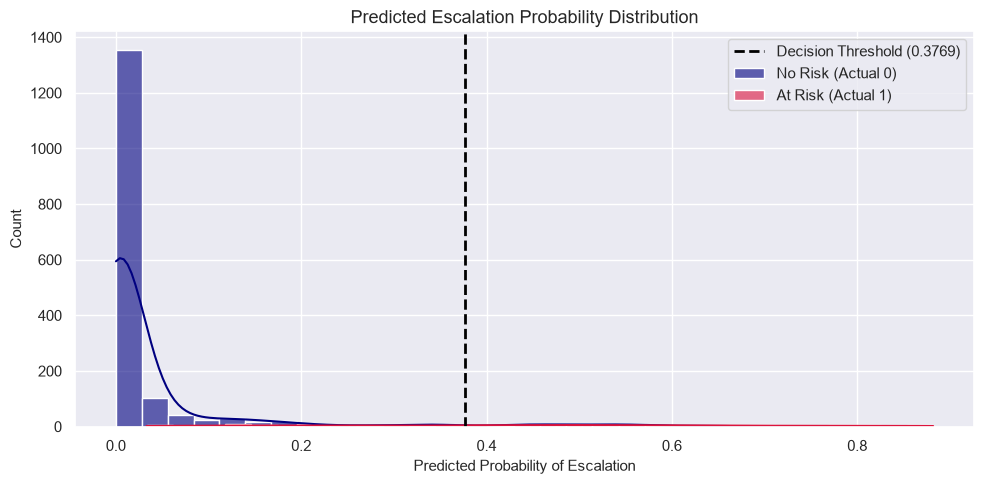

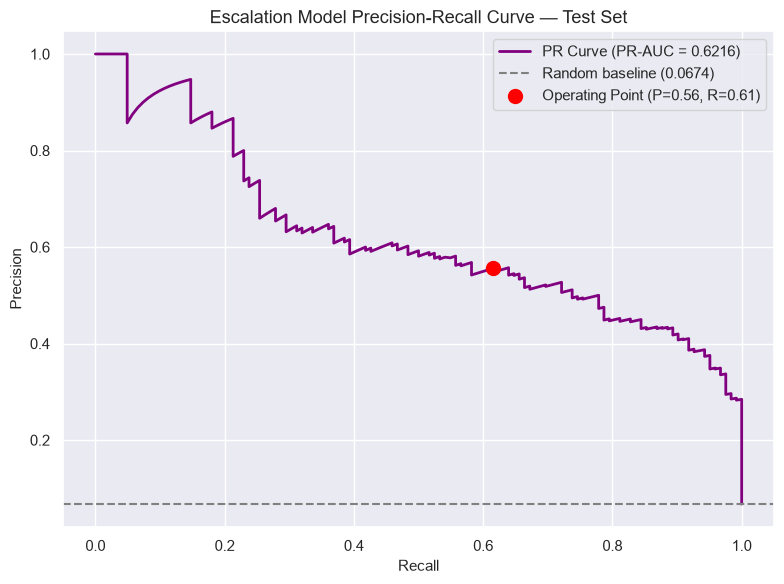

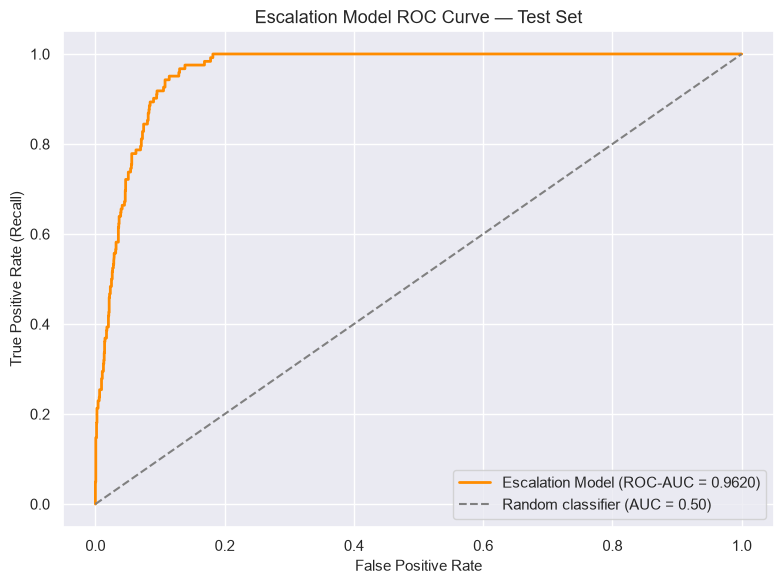

C:\Users\user\AppData\Local\Temp\ipykernel_12976\4183233306.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp_esc.values, y=imp_esc.index, palette="rocket")


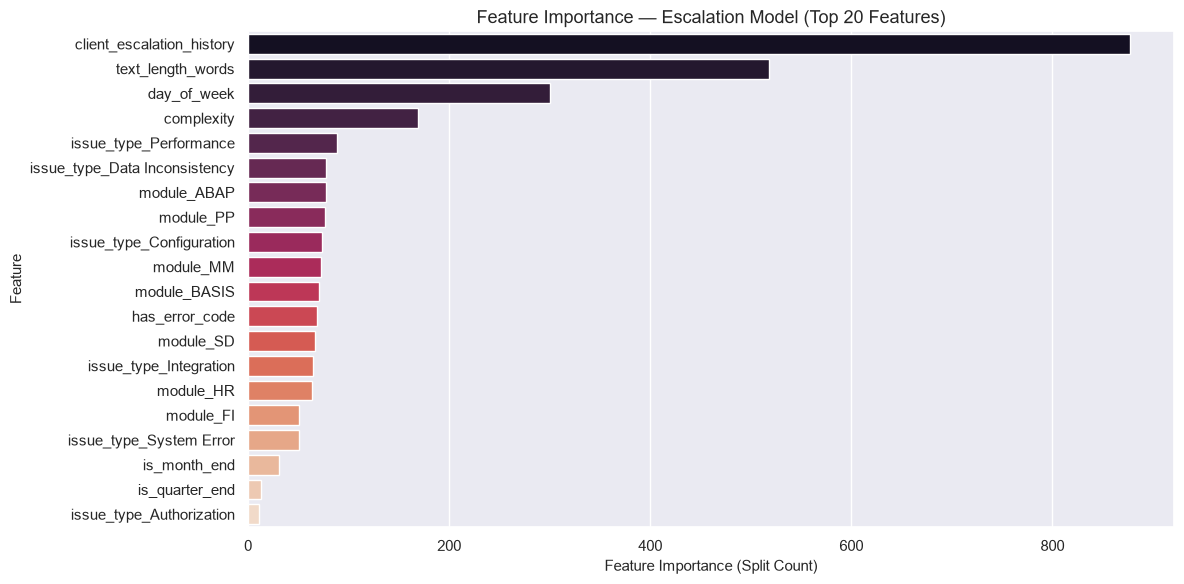

In [15]:
# ── CHART 1: CONFUSION MATRIX (AT SELECTED THRESHOLD) ─────────────────────────
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, test_preds)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Reds",
    xticklabels=["No Risk", "At Risk"],
    yticklabels=["No Risk", "At Risk"],
)
plt.title(f"Escalation Model Confusion Matrix (Threshold = {decision_threshold:.4f}) — Test Set", fontsize=13)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
plt.tight_layout()
plt.show()

# ── CHART 2: PROBABILITY DISTRIBUTION HISTOGRAM ───────────────────────────────
plt.figure(figsize=(10, 5))
sns.histplot(
    test_proba[y_test == 0], bins=30, color="navy", alpha=0.6,
    label="No Risk (Actual 0)", kde=True,
)
sns.histplot(
    test_proba[y_test == 1], bins=30, color="crimson", alpha=0.6,
    label="At Risk (Actual 1)", kde=True,
)
plt.axvline(
    decision_threshold, color="black", linestyle="--", linewidth=2,
    label=f"Decision Threshold ({decision_threshold:.4f})",
)
plt.title("Predicted Escalation Probability Distribution", fontsize=13)
plt.xlabel("Predicted Probability of Escalation", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ── CHART 3: PRECISION-RECALL CURVE ───────────────────────────────────────────
p_curve, r_curve, _ = precision_recall_curve(y_test, test_proba)
plt.figure(figsize=(8, 6))
plt.plot(r_curve, p_curve, color="purple", lw=2, label=f"PR Curve (PR-AUC = {pr_auc:.4f})")
plt.axhline(
    pr_baseline, color="gray", linestyle="--", lw=1.5,
    label=f"Random baseline ({pr_baseline:.4f})",
)
plt.scatter(
    [esc_recall], [esc_precision], color="red", s=100, zorder=5,
    label=f"Operating Point (P={esc_precision:.2f}, R={esc_recall:.2f})",
)
plt.title("Escalation Model Precision-Recall Curve — Test Set", fontsize=13)
plt.xlabel("Recall", fontsize=11)
plt.ylabel("Precision", fontsize=11)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ── CHART 4: ROC CURVE WITH AUC SCORE ─────────────────────────────────────────
fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Escalation Model (ROC-AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Random classifier (AUC = 0.50)")
plt.title("Escalation Model ROC Curve — Test Set", fontsize=13)
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate (Recall)", fontsize=11)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ── CHART 5: TOP 20 FEATURE IMPORTANCES ───────────────────────────────────────
plt.figure(figsize=(12, 6))
imp_esc = pd.Series(
    escalation_model.feature_importances_, index=X.columns
).sort_values(ascending=False).head(20)

sns.barplot(x=imp_esc.values, y=imp_esc.index, palette="rocket")
plt.title("Feature Importance — Escalation Model (Top 20 Features)", fontsize=13)
plt.xlabel("Feature Importance (Split Count)", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.tight_layout()
plt.show()

# 4. Save Model Artifacts & Final Summary

## Overview
This section exports the model metadata manifest (`lightgbm_models_meta.json`), mirrors the model artifacts into `backend/models/lightgbm/` for backend API serving, and prints the final metrics report.

In [16]:
# Assemble and export complete metadata manifest
models_meta = {
    "escalation": {
        "model_file":            ESCALATION_MODEL_PATH,
        "num_classes":           2,
        "class_names":           ["No Risk", "At Risk"],
        "best_iteration":        int(escalation_model.best_iteration_),
        "label_source": (
            "Derived from escalated column in resolved_tickets_clean.csv, "
            "which was generated by our synthetic data generator (resolution time > 120 min). "
            "Synthetic - retrain on real SLA outcomes in production."
        ),
        "decision_threshold":    round(float(decision_threshold), 4),
        "threshold_method":      threshold_method,
        "threshold_selected_on": "validation set",
        "min_recall_target":     float(MIN_RECALL_TARGET),
        "test_metrics": {
            "accuracy":    round(float(esc_accuracy),    4),
            "f1_weighted": round(float(esc_f1_weighted), 4),
            "f1_macro":    round(float(esc_f1_macro),    4),
            "precision":   round(float(esc_precision),   4),
            "recall":      round(float(esc_recall),      4),
            "f1_at_risk":  round(float(esc_f1_at_risk),  4),
            "auc":         round(float(auc_score),       4),
            "pr_auc":      round(float(pr_auc),          4),
        },
        "cv_metrics": {
            "pr_auc_mean":  round(float(cv_pr_auc_mean),  4),
            "pr_auc_std":   round(float(cv_pr_auc_std),   4),
            "roc_auc_mean": round(float(cv_auc_mean),     4),
            "roc_auc_std":  round(float(cv_auc_std),      4),
        },
    },
    "feature_names_file": FEATURE_NAMES_PATH,
    "threshold_note": (
        "The backend predictor MUST classify At Risk using decision_threshold "
        "from this file, not 0.5. The raw probability is also returned as the risk score."
    ),
    "intake_note": (
        "Stage 0 is DistilBERT intake routing (incident vs development). "
        "Development tickets are routed out; only incident tickets proceed "
        "to Stage 1 (BERT) and Stage 2 (LightGBM)."
    ),
    "why_no_urgency": (
        "Urgency has no real ground truth in our dataset. "
        "Synthetic probability-based labels produce noisy "
        "unlearnable signal — identical features get different "
        "labels by random chance. Removed to maintain integrity."
    ),
    "complexity_note": (
        "complexity is an INPUT FEATURE derived from issue_type "
        "via COMPLEXITY_MAP at training time. At inference time "
        "BERT's complexity prediction is used instead. "
        "Maps: Simple=0, Medium=1, Complex=2"
    ),
    "inference_note": (
        "resolution_time_minutes is NOT a feature at inference time. "
        "It does not exist when a new ticket arrives. "
        "Used only during training for data quality validation."
    ),
    "trained_on":   datetime.now().isoformat(),
    "random_state": SEED,
}

with open(MODELS_META_PATH, "w") as f:
    json.dump(models_meta, f, indent=2)

print(f"Model metadata saved: {MODELS_META_PATH}")

Model metadata saved: lightgbm_models_meta.json


In [17]:
# Mirror artifacts into backend/models/lightgbm/ for FastAPI serving
import shutil

os.makedirs(BACKEND_LGBM_DIR, exist_ok=True)

files_to_copy = [
    ESCALATION_MODEL_PATH,
    FEATURE_NAMES_PATH,
    MODELS_META_PATH,
]

for filepath in files_to_copy:
    dest = os.path.join(BACKEND_LGBM_DIR, os.path.basename(filepath))
    shutil.copy(filepath, dest)
    print(f"Copied: {filepath} → {dest}")

print(f"\nAll files saved to: {BACKEND_LGBM_DIR}")

Copied: lightgbm_escalation_model.pkl → ../backend/models/lightgbm\lightgbm_escalation_model.pkl
Copied: lightgbm_feature_names.json → ../backend/models/lightgbm\lightgbm_feature_names.json
Copied: lightgbm_models_meta.json → ../backend/models/lightgbm\lightgbm_models_meta.json

All files saved to: ../backend/models/lightgbm


In [18]:
# Print final pipeline completion summary
print("═" * 55)
print("LIGHTGBM TRAINING COMPLETE — FINAL SUMMARY")
print("═" * 55)
print()
print("Escalation Risk Model (binary: No Risk / At Risk):")
print("  Label source:          escalated column from synthetic resolved tickets")
print(f"  Decision Threshold:    {decision_threshold:.4f} ({threshold_method})")
print(f"  Test Accuracy:         {esc_accuracy:.4f}")
print(f"  Test Precision:        {esc_precision:.4f}")
print(f"  Test Recall:           {esc_recall:.4f}")
print(f"  Test F1 (At Risk):     {esc_f1_at_risk:.4f}")
print(f"  ROC-AUC Score:         {auc_score:.4f}")
print(f"  PR-AUC Score:          {pr_auc:.4f} (Baseline = {pr_baseline:.4f})")
print(f"  CV PR-AUC:             {cv_pr_auc_mean:.4f} +/- {cv_pr_auc_std:.4f}")
print(f"  CV ROC-AUC:            {cv_auc_mean:.4f} +/- {cv_auc_std:.4f}")
print()
print("Inference pipeline:")
print("  0. DistilBERT runs on ticket text (Stage 0 Intake)")
print("     → classifies incident vs development; development tickets routed out")
print("  1. BERT runs on incident ticket text (Stage 1 Classification)")
print("     → module, issue_type, complexity")
print("  2. LightGBM runs using BERT output + metadata (Stage 2 Risk)")
print("     → escalation risk probability (0.0 to 1.0) and threshold-flagged At Risk status")
print("  3. Dashboard shows all predictions to consultant")
print()
print("Files saved to backend/models/lightgbm/:")
for f in files_to_copy:
    print(f"  {os.path.basename(f)}")
print("═" * 55)

═══════════════════════════════════════════════════════
LIGHTGBM TRAINING COMPLETE — FINAL SUMMARY
═══════════════════════════════════════════════════════

Escalation Risk Model (binary: No Risk / At Risk):
  Label source:          escalated column from synthetic resolved tickets
  Decision Threshold:    0.3769 (recall_target)
  Test Accuracy:         0.9409
  Test Precision:        0.5556
  Test Recall:           0.6148
  Test F1 (At Risk):     0.5837
  ROC-AUC Score:         0.9620
  PR-AUC Score:          0.6216 (Baseline = 0.0674)
  CV PR-AUC:             0.6023 +/- 0.0346
  CV ROC-AUC:            0.9605 +/- 0.0023

Inference pipeline:
  0. DistilBERT runs on ticket text (Stage 0 Intake)
     → classifies incident vs development; development tickets routed out
  1. BERT runs on incident ticket text (Stage 1 Classification)
     → module, issue_type, complexity
  2. LightGBM runs using BERT output + metadata (Stage 2 Risk)
     → escalation risk probability (0.0 to 1.0) and threshol